# 数据结构与科学计算 · 第 07 讲
## 稀疏矩阵、COO/CSR 与二维 Poisson 方程

> **课程定位**：面向已经学习 Python 基础、正在准备自行编写二维 CFD 求解器的学习者。本讲从数据结构原理出发，以实际数值计算问题作为应用练习。

**完成本讲后，你应该能够：**

1. 理解“局部相邻”为什么导致稀疏离散矩阵；
2. 看懂 COO 的 `(row, column, value)` 记录和 CSR 的 `data / indices / indptr`；
3. 区分 COO 的**组装优势**与 CSR 的**矩阵向量乘优势**；
4. 用 Kronecker 积组装结构化网格的五点 Laplace 离散矩阵；
5. 使用 SciPy 求解二维 Dirichlet Poisson 方程，并观察网格加密收敛。

**预计学习时间**：100–150 分钟。所有核心示例可在 VS Code 的 Jupyter Notebook 中直接运行。

## 0. 使用方法与运行环境

1. 在 VS Code 打开此 `.ipynb`，右上角选择当前项目的 Python Kernel；
2. 使用 `Shift + Enter` 依次运行。修改代码后，建议 **Restart Kernel & Run All** 以消除旧变量干扰；
3. **练习单元以 `TODO` 留空**，后面会有逐项自动检查；未完成练习时显示“尚未通过”是预期行为；
4. 最后附有独立命名的 `_solution` 参考实现，不会覆盖你的练习函数；
5. 学习重点是“选择什么结构、为什么、代价是什么”，不只是背诵 API。

前两讲已安装 NumPy。本系列推荐运行 `uv pip install numpy scipy matplotlib ipykernel jupyter`。第 08 讲还需要 JAX：`uv pip install -U jax`（此命令默认安装适用于当前平台的发行版，GPU 支持视平台而定）。

In [1]:
import sys
print('Python:', sys.version.split()[0])
print('Notebook 已连接到 Python Kernel')

Python: 3.13.5
Notebook 已连接到 Python Kernel


## 1. 从 PDE 到线性方程组

二维 Poisson 方程（先考虑单位正方形、零 Dirichlet 边界）：

$$-\nabla^2 u=f,\qquad (x,y)\in(0,1)^2,\qquad u\vert_{\partial\Omega}=0.$$

用五点有限差分离散，内部网格点 $(j,i)$：

$$
-\nabla^2 u_{j,i}\approx
\frac{2u_{j,i}-u_{j,i-1}-u_{j,i+1}}{\Delta x^2}
+\frac{2u_{j,i}-u_{j-1,i}-u_{j+1,i}}{\Delta y^2}
=f_{j,i}.
$$

每个内部未知量只与自身和**最多四个邻居**相互作用，因此 $A\mathbf u=\mathbf f$ 中每行通常不超过 5 个非零值。

本讲采用 **内部节点数** `ny, nx`，网格间距 $\Delta x=1/(n_x+1)$，$\Delta y=1/(n_y+1)$。横向 $i$ 为第二维，行向 $j$ 为第一维。

## 2. 数组展平：二维索引如何映射到方程编号？

按 NumPy 默认 C 顺序（行优先）展平：

$$k=j\,n_x+i,\qquad i=k\bmod n_x,\qquad j=\left\lfloor\frac{k}{n_x}\right\rfloor.$$

这种约定使横向相邻点索引相差 1，纵向相邻点索引相差 $n_x$。**但是横向跨行处并不相邻**，直接用 `diags(...,offset=±1)` 组装二维算子必须特别小心跨行伪连接。

In [2]:
import numpy as np
ny, nx = 3, 4
index_grid = np.arange(ny*nx).reshape(ny,nx)
print('2D -> 1D mapping:\n',index_grid)
u = np.arange(ny*nx,dtype=float).reshape(ny,nx)
flat = u.ravel(order='C')
print('u[2,1]=', u[2,1], 'flat[2*nx+1]=',flat[2*nx+1])
assert np.array_equal(u,flat.reshape(ny,nx))

2D -> 1D mapping:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
u[2,1]= 9.0 flat[2*nx+1]= 9.0


## 3. 稠密矩阵与稀疏矩阵

如果未知量有 $N=n_xn_y$ 个：

- 稠密矩阵存储 $N^2$ 个数字，`float64` 内存约为 $8N^2$ 字节；
- 五点离散算子只包含约 $5N$ 个非零项；
- 大规模计算应只存储**非零条目**及其索引。

例如 $N=10,000$ 时，稠密 `float64` 矩阵仅数值数据就约 **800 MB**，而稀疏存储量随非零元个数近似线性增长（仍需计入行指针、列索引）。

In [3]:
from scipy import sparse

n = 1_000
D = sparse.diags([-1,2,-1],offsets=[-1,0,1],shape=(n,n),format='csr')

def csr_bytes(a):
    return a.data.nbytes + a.indices.nbytes + a.indptr.nbytes

print('shape:',D.shape,'nnz:',D.nnz)
print('CSR buffers (bytes):',csr_bytes(D))
print('dense float64 bytes (theoretical):',n*n*8)
print('nonzero fraction:',round(D.nnz/(n*n),5))

shape: (1000, 1000) nnz: 2998
CSR buffers (bytes): 39980
dense float64 bytes (theoretical): 8000000
nonzero fraction: 0.003


/tmp/ipykernel_2114/1937472180.py:4: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  D = sparse.diags([-1,2,-1],offsets=[-1,0,1],shape=(n,n),format='csr')


## 4. COO：适合逐项装配

COO (Coordinate) 保存三条并行数组：

- `row[t]`：第 t 个条目位于哪一行；
- `col[t]`：位于哪一列；
- `data[t]`：数值。

同一 `(row,col)` 可以被重复添加；当转换为 CSR 时，SciPy 通常会合并重复的条目。这一性质特别适合逐单元汇总有限元/有限体积贡献。

In [4]:
rows = [0,0,1,1,1,2,2,1]
cols = [0,1,0,1,2,1,2,1]
vals = [2,-1,-1,1,-1,-1,2,1]  # (1,1) 重复出现，合并后变为2
A_coo = sparse.coo_matrix((vals,(rows,cols)),shape=(3,3))
A_csr = A_coo.tocsr()
print('dense representation:\n',A_csr.toarray())
print('COO stored entries:',len(A_coo.data),'CSR nnz:',A_csr.nnz)

dense representation:
 [[ 2 -1  0]
 [-1  2 -1]
 [ 0 -1  2]]
COO stored entries: 8 CSR nnz: 7


## 5. CSR：按行压缩稀疏矩阵

CSR (Compressed Sparse Row) 包含：

- `data`：非零数值；
- `indices`：对应的列索引；
- `indptr`：每行数据起止位置，长度为 $n_{\mathrm{rows}}+1$。

第 $j$ 行的非零元素在

$$\text{data[indptr[j]:indptr[j+1]]}$$

以及对应的 `indices` 区间内。CSR 便于稀疏矩阵-向量乘，以及提取行范围；但动态插入新条目不如 COO 构建方便。

In [5]:
print('data:  ',A_csr.data)
print('indices:',A_csr.indices)
print('indptr: ',A_csr.indptr)
for j in range(A_csr.shape[0]):
    start, end = A_csr.indptr[j:j+2]
    print(f'row {j}:', list(zip(A_csr.indices[start:end],A_csr.data[start:end])))
print('A*[1,2,3]=',A_csr @ np.array([1.,2.,3.]))

data:   [ 2 -1 -1  2 -1 -1  2]
indices: [0 1 0 1 2 1 2]
indptr:  [0 2 5 7]
row 0: [(np.int32(0), np.int64(2)), (np.int32(1), np.int64(-1))]
row 1: [(np.int32(0), np.int64(-1)), (np.int32(1), np.int64(2)), (np.int32(2), np.int64(-1))]
row 2: [(np.int32(1), np.int64(-1)), (np.int32(2), np.int64(2))]
A*[1,2,3]= [0. 0. 4.]


## 6. 一维 Poisson 矩阵

对 $-u''=f$ 使用二阶中心差分，内部节点数为 $n$，边界值均为 0：

$$A=\frac{1}{h^2}
\begin{bmatrix}
2&-1&&\\[-2pt]
-1&2&-1&\\
&\ddots&\ddots&\ddots\\
&&-1&2
\end{bmatrix},\qquad h=\frac{1}{n+1}.$$

这个矩阵对称正定（SPD）。零 Dirichlet 边界的贡献已经被排除；如果是**非零边界值**，必须修改右端向量（不是只改 `f` 的物理函数取值）。

In [6]:
from scipy.sparse import diags
from scipy.sparse.linalg import spsolve

def poisson_1d(n):
    h = 1/(n+1)
    return diags([-1,2,-1],[-1,0,1],shape=(n,n),format='csr') / h**2

n=12
x=(np.arange(n)+1)/(n+1)
f=(np.pi**2)*np.sin(np.pi*x)
u_numeric=spsolve(poisson_1d(n),f)
print('1D max error:',float(np.max(np.abs(u_numeric-np.sin(np.pi*x)))))

1D max error: 0.00484532516863978


/tmp/ipykernel_2114/4088001911.py:6: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  return diags([-1,2,-1],[-1,0,1],shape=(n,n),format='csr') / h**2


## 7. 二维离散 Laplace 的 Kronecker 积组装

设 $T_x$ 是 x 向一维离散 $-\partial_{xx}$，$T_y$ 是 y 向的对应矩阵。行优先展平时：

$$A=I_y\otimes T_x + T_y\otimes I_x.$$

这自动保证相邻关系不会跨行错误连接。对固定矩形结构化网格非常直观。对复杂非结构化网格，通常按各单元或面贡献建立 COO。

In [7]:
def poisson_matrix_2d(ny, nx, dx, dy):
    if nx < 1 or ny < 1 or dx <= 0 or dy <= 0:
        raise ValueError('grid dimensions/spacing must be positive')
    tx = sparse.diags([-1,2,-1],[-1,0,1],shape=(nx,nx),format='csr') / dx**2
    ty = sparse.diags([-1,2,-1],[-1,0,1],shape=(ny,ny),format='csr') / dy**2
    ix, iy = sparse.eye(nx,format='csr'), sparse.eye(ny,format='csr')
    return (sparse.kron(iy,tx,format='csr') +
            sparse.kron(ty,ix,format='csr')).tocsr()

M = poisson_matrix_2d(2,3,0.25,0.2)
print('shape:',M.shape,'nnz:',M.nnz)
print('6x6 Poisson stencil matrix:\n',M.toarray())
print('matrix symmetric?',np.allclose(M.toarray(),M.toarray().T))

shape: (6, 6) nnz: 20
6x6 Poisson stencil matrix:
 [[ 82. -16.   0. -25.   0.   0.]
 [-16.  82. -16.   0. -25.   0.]
 [  0. -16.  82.   0.   0. -25.]
 [-25.   0.   0.  82. -16.   0.]
 [  0. -25.   0. -16.  82. -16.]
 [  0.   0. -25.   0. -16.  82.]]
matrix symmetric? True


/tmp/ipykernel_2114/3440260322.py:4: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  tx = sparse.diags([-1,2,-1],[-1,0,1],shape=(nx,nx),format='csr') / dx**2
/tmp/ipykernel_2114/3440260322.py:5: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  ty = sparse.diags([-1,2,-1],[-1,0,1],shape=(ny,ny),format='csr') / dy**2


## 8. 实际求解：二维 Dirichlet Poisson 方程

采用有解析解的制造解（manufactured solution）验证离散化：

$$u_{\mathrm{exact}}(x,y)=\sin(\pi x)\sin(\pi y),$$
$$f(x,y)=2\pi^2\sin(\pi x)\sin(\pi y).$$

这满足 $-\nabla^2u=f$ 与零 Dirichlet 边界。网格加密时，最大范数误差通常表现出 $O(h^2)$ 趋势。

**注意**：此处求解的是标量椭圆方程，并不是直接求得圆柱绕流；不过压力修正/投影等 CFD 步骤会出现密切相关的 Poisson 型线性系统。

In [8]:
def solve_manufactured(ny, nx):
    dx,dy=1/(nx+1),1/(ny+1)
    xs=np.arange(1,nx+1)*dx
    ys=np.arange(1,ny+1)*dy
    X,Y=np.meshgrid(xs,ys,indexing='xy')
    exact=np.sin(np.pi*X)*np.sin(np.pi*Y)
    f=2*np.pi**2*exact
    A=poisson_matrix_2d(ny,nx,dx,dy)
    numerical=spsolve(A,f.ravel()).reshape(ny,nx)
    max_error=np.max(np.abs(numerical-exact))
    residual=np.linalg.norm(A @ numerical.ravel()-f.ravel())
    return numerical,exact,max_error,residual,A

for n in [8,16,32]:
    _,_,e,res,A=solve_manufactured(n,n)
    print(f'n={n:>2}, DOF={n*n:>4}, nnz={A.nnz:>5}, error={e:.4e}, residual={res:.2e}')

n= 8, DOF=  64, nnz=  288, error=9.9080e-03, residual=2.17e-13
n=16, DOF= 256, nnz= 1216, error=2.8265e-03, residual=1.37e-12
n=32, DOF=1024, nnz= 4992, error=7.5388e-04, residual=1.08e-11


/tmp/ipykernel_2114/3440260322.py:4: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  tx = sparse.diags([-1,2,-1],[-1,0,1],shape=(nx,nx),format='csr') / dx**2
/tmp/ipykernel_2114/3440260322.py:5: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  ty = sparse.diags([-1,2,-1],[-1,0,1],shape=(ny,ny),format='csr') / dy**2


/tmp/ipykernel_2114/3440260322.py:4: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  tx = sparse.diags([-1,2,-1],[-1,0,1],shape=(nx,nx),format='csr') / dx**2
/tmp/ipykernel_2114/3440260322.py:5: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  ty = sparse.diags([-1,2,-1],[-1,0,1],shape=(ny,ny),format='csr') / dy**2


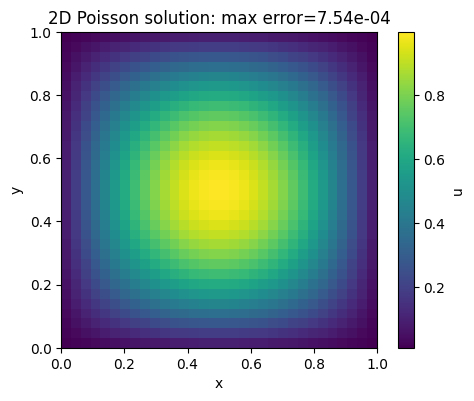

In [9]:
import matplotlib.pyplot as plt
numerical,exact,error,residual,A=solve_manufactured(32,32)
fig,ax=plt.subplots(figsize=(5.4,4.1))
im=ax.imshow(numerical,origin='lower',extent=(0,1,0,1),cmap='viridis')
fig.colorbar(im,ax=ax,label='u')
ax.set(title=f'2D Poisson solution: max error={error:.2e}',xlabel='x',ylabel='y')
plt.show()

### 8.1 SciPy 稀疏求解器选择

- `spsolve`：通用稀疏直接法，适合中小型验证问题，可能产生大量 fill-in，内存未必随 nnz 线性增长；
- `cg`：适用于对称正定矩阵的迭代求解，性能依赖预条件；
- `gmres` 等：适用于更一般的线性系统；
- 边界条件决定矩阵性质。例如**纯 Neumann** 的 Laplace 系统通常存在常数零空间，需要额外处理，不能直接照搬当前零 Dirichlet 设定。

本讲重点是**数据布局与组装**，不是系统讲解所有求解器。

---
## 9. 编程练习

**练习 1：** 实现 `flatten_index(j,i,nx)` 和 `unflatten_index(k,nx)`，采用行优先顺序，返回整数或 `(j,i)`；假设输入非负且合法。

In [10]:
def flatten_index(j, i, nx):
    # TODO: j*nx+i
    return None

def unflatten_index(k, nx):
    # TODO: divmod
    return None

**练习 2：** 实现 `tridiag_poisson_1d(n)`：返回大小为 `n×n` 的 CSR 矩阵，对应零 Dirichlet 的 `-u''`；内部网格距离 `h=1/(n+1)`。

In [11]:
def tridiag_poisson_1d(n):
    # TODO: scipy.sparse.diags + CSR
    return None

**练习 3：** 实现 `assemble_poisson_coo(ny,nx,dx,dy)`，**逐行填充 COO 三元组**并转换为 CSR。矩阵作用于内部自由度，边界值为零。提示：中心系数 `2/dx²+2/dy²`，合法邻居的系数为对应的 `-1/h²`。

In [12]:
def assemble_poisson_coo(ny,nx,dx,dy):
    # TODO: rows, cols, vals；注意横向不能错误跨行
    return None

## 练习自测

运行下方测试。`TODO` 未完成时出现“尚未通过”属于正常情况；逐项填入你的实现并再次运行。本讲的测试检查正确性与边界条件，性能优化可在通过后继续尝试。

In [13]:
def check(name, test_fn):
    try:
        test_fn()
        print(f"✅ {name}：通过")
    except Exception as exc:
        print(f"⬜ {name}：尚未通过 — {type(exc).__name__}: {exc}")

In [14]:
def test_ex1():
    for ny, nx in [(2,4),(6,7)]:
        for j in range(ny):
            for i in range(nx):
                k=flatten_index(j,i,nx)
                assert k == j*nx+i
                assert unflatten_index(k,nx) == (j,i)

def test_ex2():
    for n in [1,2,8]:
        a=tridiag_poisson_1d(n)
        assert sparse.isspmatrix_csr(a),'must return csr_matrix'
        assert np.allclose(a.toarray(), poisson_1d(n).toarray())

def test_ex3():
    for ny,nx in [(1,1),(2,3),(4,2)]:
        a=assemble_poisson_coo(ny,nx,0.2,0.3)
        ref=poisson_matrix_2d(ny,nx,0.2,0.3)
        assert sparse.isspmatrix_csr(a),'must return csr_matrix'
        assert a.shape == ref.shape
        assert np.allclose(a.toarray(),ref.toarray())

check('练习 1 / 展平索引',test_ex1)
check('练习 2 / 一维三对角矩阵',test_ex2)
check('练习 3 / COO 五点算子组装',test_ex3)

⬜ 练习 1 / 展平索引：尚未通过 — AssertionError: 
⬜ 练习 2 / 一维三对角矩阵：尚未通过 — AssertionError: must return csr_matrix
⬜ 练习 3 / COO 五点算子组装：尚未通过 — AssertionError: must return csr_matrix


/tmp/ipykernel_2114/3440260322.py:4: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  tx = sparse.diags([-1,2,-1],[-1,0,1],shape=(nx,nx),format='csr') / dx**2
/tmp/ipykernel_2114/3440260322.py:5: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  ty = sparse.diags([-1,2,-1],[-1,0,1],shape=(ny,ny),format='csr') / dy**2


## 10. 参考答案（可以与 Kronecker 实现比较）

In [15]:
def flatten_index_solution(j,i,nx):
    return j*nx+i

def unflatten_index_solution(k,nx):
    return divmod(k,nx)

def tridiag_poisson_1d_solution(n):
    if n < 1:
        raise ValueError('n must be positive')
    h=1/(n+1)
    return sparse.diags([-1,2,-1],[-1,0,1],shape=(n,n),format='csr')/h**2

def assemble_poisson_coo_solution(ny,nx,dx,dy):
    if nx < 1 or ny < 1 or dx <= 0 or dy <= 0:
        raise ValueError('invalid grid')
    rows,cols,values=[],[],[]
    def add(row,col,value):
        rows.append(row)
        cols.append(col)
        values.append(value)
    for j in range(ny):
        for i in range(nx):
            k=j*nx+i
            add(k,k,2/dx**2+2/dy**2)
            if i>0:
                add(k,k-1,-1/dx**2)
            if i<nx-1:
                add(k,k+1,-1/dx**2)
            if j>0:
                add(k,k-nx,-1/dy**2)
            if j<ny-1:
                add(k,k+nx,-1/dy**2)
    return sparse.coo_matrix((values,(rows,cols)),shape=(ny*nx,ny*nx)).tocsr()

assert unflatten_index_solution(flatten_index_solution(3,2,7),7) == (3,2)
assert np.allclose(assemble_poisson_coo_solution(3,4,0.1,0.2).toarray(),
                   poisson_matrix_2d(3,4,0.1,0.2).toarray())
print('✅ 参考答案自测通过')

✅ 参考答案自测通过


/tmp/ipykernel_2114/3440260322.py:4: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  tx = sparse.diags([-1,2,-1],[-1,0,1],shape=(nx,nx),format='csr') / dx**2
/tmp/ipykernel_2114/3440260322.py:5: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  ty = sparse.diags([-1,2,-1],[-1,0,1],shape=(ny,ny),format='csr') / dy**2


## 11. 对比：网格加密时的误差比例

对二阶精度方法，加密近一倍后误差通常约为原先的 $1/4$（足够细的网格进入渐近收敛区时）。计算最大范数误差比例。

In [16]:
errors=[]
for n in (12,24,48):
    _,_,err,_,_=solve_manufactured(n,n)
    errors.append(err)
print('max errors:',[f'{e:.4e}' for e in errors])
print('coarse/fine error ratios:',[round(a/b,3) for a,b in zip(errors,errors[1:])])

max errors: ['4.8100e-03', '1.3118e-03', '3.4227e-04']
coarse/fine error ratios: [np.float64(3.667), np.float64(3.833)]


/tmp/ipykernel_2114/3440260322.py:4: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  tx = sparse.diags([-1,2,-1],[-1,0,1],shape=(nx,nx),format='csr') / dx**2
/tmp/ipykernel_2114/3440260322.py:5: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  ty = sparse.diags([-1,2,-1],[-1,0,1],shape=(ny,ny),format='csr') / dy**2


## 12. 自测与扩展

1. 为什么二维五点差分矩阵每行只有少量非零值？
2. 组装矩阵时 COO 与求解时 CSR 分别有哪些优势？
3. 为什么不能简单用 `offset=+1` 表示所有横向相邻点？
4. 对于 Poisson 方程，Dirichlet 与 Neumann 边界条件对线性系统有什么影响？
5. `spsolve` 在大规模问题上为什么未必总比迭代法更省内存？

**下一讲**：将数值数组、函数式编程和 JAX 自动微分连接起来，构建一个小型可微分数值时间积分器。